# PlateCheck — C2 mass regressor (team-trained neural stage)
**Owner:** P1 · **Job:** photo → total food mass (grams). C1 says *what* is on the plate; C2 says *how much*; C3 combines them.

Notebook order matches the Nov 22 Progress requirement: **loaded data → runnable baseline → inspectable attempt → diagnosis**.

Runtime → Change runtime type → **T4 GPU** before running.

## 0. Config

In [ ]:
import os, re, json, time, random, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import torchvision
from torchvision.transforms import v2 as T
from PIL import Image

CFG = dict(
    DATA_DIR   = os.environ.get("N5K_DIR", "/content/n5k"),       # fast local disk (images)
    OUT_DIR    = os.environ.get("OUT_DIR", "/content/drive/MyDrive/PlateCheck/C2_runA"),
    BUCKET_URL = "https://storage.googleapis.com/nutrition5k_dataset/nutrition5k_dataset",
    IMG        = 224,      # C2 input size (proposal)
    BATCH      = 32,
    EPOCHS     = int(os.environ.get("EPOCHS", 30)),
    PATIENCE   = 6,        # early stopping: epochs without a new validation low
    LR_HEAD    = 1e-3,
    LR_BACKBONE= 1e-4,
    VAL_FRAC   = 0.15,
    PLATE_GAP_S= 600,      # max seconds between incremental scans of the same plate
    SEED       = 539,
    PRETRAINED = os.environ.get("PRETRAINED", "1") == "1",
    FINAL_EVAL = False,    # flip to True ONCE, after code freeze (Fair test rule)
)
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


In [ ]:
# Mount Drive so checkpoints/splits survive a Colab disconnect (skip if not on Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
DATA, OUT = Path(CFG["DATA_DIR"]), Path(CFG["OUT_DIR"])
DATA.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data access (selective download, not the 181 GB archive)
Only the metadata CSVs, the official split files, and `realsense_overhead/<dish>/rgb.png` for dishes in the RGB splits. Re-running skips files already on disk.

In [ ]:
import requests
from concurrent.futures import ThreadPoolExecutor

def fetch(rel, dst):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0: return True
    dst.parent.mkdir(parents=True, exist_ok=True)
    r = requests.get(f"{CFG['BUCKET_URL']}/{rel}", timeout=60)
    if r.status_code != 200: return False
    dst.write_bytes(r.content); return True

META_FILES  = ["metadata/dish_metadata_cafe1.csv", "metadata/dish_metadata_cafe2.csv"]
SPLIT_FILES = ["dish_ids/splits/rgb_train_ids.txt", "dish_ids/splits/rgb_test_ids.txt"]
for f in META_FILES + SPLIT_FILES:
    assert fetch(f, DATA/f), f"could not download {f}"

read_ids = lambda f: [l.strip() for l in open(DATA/f) if l.strip()]
official_train, official_test = read_ids(SPLIT_FILES[0]), read_ids(SPLIT_FILES[1])
print(f"official RGB split: {len(official_train)} train, {len(official_test)} test")

def img_path(d): return DATA/"imagery/realsense_overhead"/d/"rgb.png"
def fetch_img(d): return d, fetch(f"imagery/realsense_overhead/{d}/rgb.png", img_path(d))

if os.environ.get("SKIP_DOWNLOAD") != "1":
    t0 = time.time()
    with ThreadPoolExecutor(32) as ex:
        res = list(ex.map(fetch_img, official_train + official_test))
    missing = [d for d, ok in res if not ok]
    print(f"images: {len(res)-len(missing)} ok, {len(missing)} missing, {time.time()-t0:.0f}s")

official RGB split: 4059 train, 709 test
images: 3262 ok, 1506 missing, 7s


## 2. Parse metadata
Rows are variable length: 6 dish fields, then 7 fields per ingredient `(id, name, grams, kcal, fat, carb, protein)`.

In [ ]:
rows = []
for f in META_FILES:
    for line in open(DATA/f):
        p = line.rstrip("\n").split(",")
        if len(p) < 6 or not p[0].startswith("dish_"): continue
        ingr = [(p[i], p[i+1], float(p[i+2])) for i in range(6, len(p) - 6, 7)]
        rows.append(dict(dish_id=p[0], total_calories=float(p[1]), total_mass=float(p[2]),
                         total_fat=float(p[3]), total_carb=float(p[4]), total_protein=float(p[5]),
                         ingr_ids=frozenset(i[0] for i in ingr),
                         ingr_names=[i[1] for i in ingr], n_ingr=len(ingr)))
meta = pd.DataFrame(rows).drop_duplicates("dish_id").set_index("dish_id")

def usable(ids):
    ids = [d for d in ids if d in meta.index and img_path(d).exists()]
    return [d for d in ids if meta.at[d, "total_mass"] > 0]   # validity check only, no label peeking
train_all, test_ids = usable(official_train), usable(official_test)
print(f"usable: {len(train_all)} train, {len(test_ids)} test")
meta.loc[train_all, ["total_mass", "total_calories", "n_ingr"]].describe().round(1)

usable: 2755 train, 507 test


,total_mass,total_calories,n_ingr
count,2755.0,2755.0,2755.0
mean,218.0,254.9,7.4
std,163.1,221.0,6.9
min,5.0,0.0,1.0
25%,94.0,81.8,1.0
50%,179.0,208.1,4.0
75%,308.0,376.6,12.0
max,3051.0,3943.3,34.0


## 3. Plate-grouped validation split (leakage control)
Nutrition5k plates were scanned **incrementally** (scan, add an ingredient, scan again), and each scan is its own `dish_id`. Two scans of one plate are near-duplicate images, so splitting by dish would leak.
`dish_id` is a Unix timestamp. Heuristic: consecutive dishes belong to the same plate if they're < `PLATE_GAP_S` apart **and** the later ingredient set contains the earlier one. **Eyeball the printed groups** — this is your Progress-report evidence that the split is sound.

In [ ]:
def ts(d):
    m = re.match(r"dish_(\d+)", d); return int(m.group(1)) if m else None

def plate_groups(ids):
    ids = sorted(ids, key=lambda d: (ts(d) is None, ts(d) or 0, d))
    gid, groups, prev = -1, {}, None
    for d in ids:
        same = (prev is not None and ts(d) is not None and ts(prev) is not None
                and ts(d) - ts(prev) < CFG["PLATE_GAP_S"]
                and meta.at[prev, "ingr_ids"] <= meta.at[d, "ingr_ids"])
        if not same: gid += 1
        groups[d] = gid; prev = d
    return pd.Series(groups)

g = plate_groups(train_all)
sizes = g.value_counts()
print(f"{len(train_all)} train dishes -> {g.nunique()} plates; group size: mean {sizes.mean():.2f}, max {sizes.max()}")
for p in sizes.index[:3]:   # largest groups: masses and ingredient counts should increase
    ds = g[g == p].index
    print(f"plate {p}:", [(int(meta.at[d,'total_mass']), int(meta.at[d,'n_ingr'])) for d in ds])

2755 train dishes -> 1032 plates; group size: mean 2.67, max 9
plate 466: [(42, 1), (131, 2), (183, 3), (211, 10), (254, 11), (317, 12), (341, 16), (362, 21), (427, 22)]
plate 1018: [(90, 1), (162, 10), (281, 20), (325, 21), (364, 22), (400, 23), (423, 24), (440, 25), (497, 29)]
plate 922: [(47, 1), (80, 10), (140, 17), (163, 18), (262, 19), (322, 20), (418, 21), (464, 25)]


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=CFG["VAL_FRAC"], random_state=CFG["SEED"])
tr_idx, va_idx = next(gss.split(train_all, groups=g.loc[train_all].values))
train_ids = [train_all[i] for i in tr_idx]; val_ids = [train_all[i] for i in va_idx]
assert not set(g.loc[train_ids]) & set(g.loc[val_ids]), "a plate is in both train and val"
print(f"train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)} (untouched)")

# Deliverable: fixed split files the whole team uses
pd.DataFrame({"dish_id": train_ids + val_ids + test_ids,
              "split": ["train"]*len(train_ids) + ["val"]*len(val_ids) + ["test"]*len(test_ids),
              "plate_group": list(g.loc[train_ids]) + list(g.loc[val_ids]) + [-1]*len(test_ids)}
            ).to_csv(OUT/"splits.csv", index=False)

train 2301 | val 454 | test 507 (untouched)


## 4. Baseline: fixed portion (median training mass)
Predicting one constant for every dish. The median is the constant that minimizes MAE on the training set. C2 is only useful if it beats this.

In [ ]:
y_tr = meta.loc[train_ids, "total_mass"].values
y_va = meta.loc[val_ids,   "total_mass"].values
MEDIAN, MU, SD = float(np.median(y_tr)), float(y_tr.mean()), float(y_tr.std())
mae = lambda a, b: float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
baseline = pd.DataFrame({
    "val mass MAE (g)": [mae(y_va, MEDIAN), mae(y_va, MU)],
}, index=[f"median ({MEDIAN:.0f} g)", f"mean ({MU:.0f} g)"]).round(1)
baseline

,val mass MAE (g)
median (178 g),121.1
mean (217 g),122.7


## 5. Preprocessing and augmentation
* **Pad to square, then resize to 224.** Center-cropping a 640×480 frame can cut food off the plate edge, which directly corrupts a *mass* target.
* **Augment with flips, 90° rotations, color jitter only.** No random zoom/crop: in an overhead rig at fixed height, apparent size *is* the portion signal. Zooming would teach the model that a plate's size is arbitrary.
* Images are decoded once and cached as uint8 tensors, so epochs don't re-decode PNGs.

In [ ]:
def load_square(d, size=CFG["IMG"]):
    im = Image.open(img_path(d)).convert("RGB")
    w, h = im.size; s = max(w, h)
    canvas = Image.new("RGB", (s, s)); canvas.paste(im, ((s - w)//2, (s - h)//2))
    return torch.from_numpy(np.array(canvas.resize((size, size), Image.BILINEAR))).permute(2, 0, 1).contiguous()

def build_cache(ids, name):
    f = OUT/f"cache_{name}_{CFG['IMG']}.pt"
    if f.exists():
        c = torch.load(f)
        if c["ids"] == ids: return c["x"]
    x = torch.stack([load_square(d) for d in ids]); torch.save({"ids": ids, "x": x}, f); return x

X_tr, X_va = build_cache(train_ids, "train"), build_cache(val_ids, "val")
print("cached:", tuple(X_tr.shape), tuple(X_va.shape))

NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # ImageNet stats (pretrained backbone)
class Rot90:
    def __call__(self, x): return torch.rot90(x, random.randint(0, 3), dims=(-2, -1))
train_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomVerticalFlip(), Rot90(),
                      T.ColorJitter(0.3, 0.3, 0.3, 0.03), T.ToDtype(torch.float32, scale=True), NORM])
eval_tf  = T.Compose([T.ToDtype(torch.float32, scale=True), NORM])

class MassDS(torch.utils.data.Dataset):
    def __init__(self, X, ids, tf):
        self.X, self.tf = X, tf
        self.y = torch.tensor((meta.loc[ids, "total_mass"].values - MU) / SD, dtype=torch.float32)  # standardized target
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(self.X[i]), self.y[i]

dl_tr = torch.utils.data.DataLoader(MassDS(X_tr, train_ids, train_tf), CFG["BATCH"], shuffle=True, num_workers=2, drop_last=True)
dl_va = torch.utils.data.DataLoader(MassDS(X_va, val_ids, eval_tf), 64, num_workers=2)

cached: (2301, 3, 224, 224) (454, 3, 224, 224)


## 6. Model: ResNet-18 (ImageNet init) + 1-unit regression head
Same linear-output regression as the course activities, except the input features **h** come from a CNN instead of raw x: ŷ = wᵀh + b, h ∈ ℝ⁵¹². Target is standardized, z = (mass − μ)/σ, so the MSE gradients are O(1) instead of O(10⁴ g²).

In [ ]:
def make_model(pretrained=CFG["PRETRAINED"]):
    w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = torchvision.models.resnet18(weights=w)
    m.fc = nn.Linear(m.fc.in_features, 1)          # the new regression head
    return m

model = make_model().to(DEVICE)
head = list(model.fc.parameters()); head_ids = {id(p) for p in head}
backbone = [p for p in model.parameters() if id(p) not in head_ids]
opt = torch.optim.Adam([{"params": backbone, "lr": CFG["LR_BACKBONE"]},
                        {"params": head,     "lr": CFG["LR_HEAD"]}])
loss_fn = nn.MSELoss()
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["EPOCHS"])
print(f"trainable params: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")

trainable params: 11.2 M


## 7. Train with per-epoch checkpoints and early stopping

In [ ]:
@torch.no_grad()
def predict_grams(m, dl):
    m.eval(); out = []
    for x, _ in dl: out.append(m(x.to(DEVICE)).squeeze(1).float().cpu())
    return torch.cat(out).numpy() * SD + MU

scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
hist, best, bad = [], float("inf"), 0
for ep in range(1, CFG["EPOCHS"] + 1):
    model.train(); t0, tot, n = time.time(), 0.0, 0
    for x, y in dl_tr:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            loss = loss_fn(model(x).squeeze(1).float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(y); n += len(y)
    va_mae = mae(predict_grams(model, dl_va), y_va)
    sched.step()
    hist.append(dict(epoch=ep, train_mse_std=tot/n, val_mae_g=va_mae, sec=time.time()-t0))
    torch.save({"model": model.state_dict(), "epoch": ep, "MU": MU, "SD": SD, "cfg": CFG}, OUT/"c2_last.pt")   # overwritten each epoch
    flag = ""
    if va_mae < best: best, bad, flag = va_mae, 0, "  * new best"; torch.save(torch.load(OUT/"c2_last.pt"), OUT/"c2_best.pt")
    else: bad += 1
    print(f"ep {ep:2d} | train MSE(std) {tot/n:.3f} | val MAE {va_mae:6.1f} g | {time.time()-t0:4.0f}s{flag}")
    if bad >= CFG["PATIENCE"]: print(f"early stop: {CFG['PATIENCE']} epochs without a new val low"); break

ck = torch.load(OUT/"c2_best.pt"); model.load_state_dict(ck["model"])
pd.DataFrame(hist).to_csv(OUT/"c2_history.csv", index=False)
print(f"restored best epoch {ck['epoch']} (val MAE {best:.1f} g)")

ep  1 | train MSE(std) 0.577 | val MAE   75.4 g |   18s  * new best
ep  2 | train MSE(std) 0.383 | val MAE   80.7 g |   17s
ep  3 | train MSE(std) 0.349 | val MAE   50.4 g |   18s  * new best
ep  4 | train MSE(std) 0.322 | val MAE   83.1 g |   19s
ep  5 | train MSE(std) 0.289 | val MAE   58.8 g |   18s
ep  6 | train MSE(std) 0.268 | val MAE   63.9 g |   17s
ep  7 | train MSE(std) 0.262 | val MAE   50.3 g |   18s  * new best
ep  8 | train MSE(std) 0.124 | val MAE   43.1 g |   19s  * new best
ep  9 | train MSE(std) 0.246 | val MAE   45.2 g |   19s
ep 10 | train MSE(std) 0.208 | val MAE   46.1 g |   17s
ep 11 | train MSE(std) 0.215 | val MAE   52.4 g |   17s
ep 12 | train MSE(std) 0.199 | val MAE   47.2 g |   17s
ep 13 | train MSE(std) 0.239 | val MAE   76.4 g |   17s
ep 14 | train MSE(std) 0.164 | val MAE   46.4 g |   18s
early stop: 6 epochs without a new val low
restored best epoch 8 (val MAE 43.1 g)


## 8. Results and diagnosis

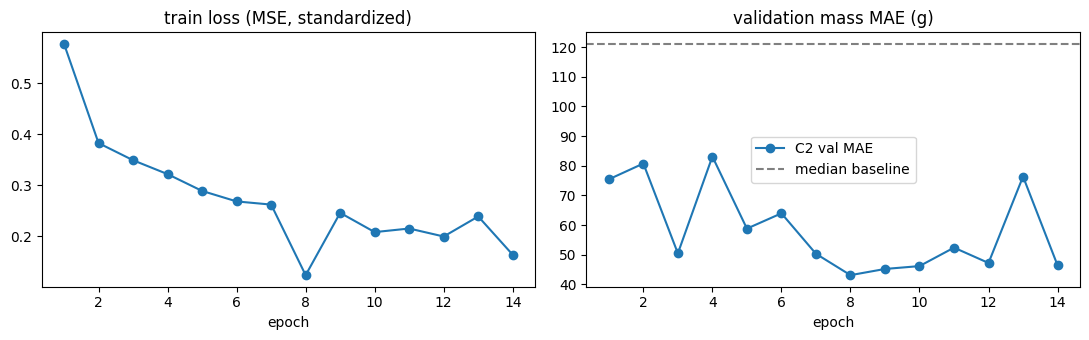

,val mass MAE (g),n
median baseline,121.1,454
C2 (best epoch),43.1,454


In [ ]:
H = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(H.epoch, H.train_mse_std, "o-"); ax[0].set(title="train loss (MSE, standardized)", xlabel="epoch")
ax[1].plot(H.epoch, H.val_mae_g, "o-", label="C2 val MAE")
ax[1].axhline(mae(y_va, MEDIAN), ls="--", c="gray", label="median baseline")
ax[1].set(title="validation mass MAE (g)", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/"c2_curves.png", dpi=150); plt.show()

p_va = predict_grams(model, dl_va)
summary = pd.DataFrame({"val mass MAE (g)": [mae(y_va, MEDIAN), mae(y_va, p_va)],
                        "n": [len(y_va)]*2}, index=["median baseline", "C2 (best epoch)"]).round(1)
summary.to_csv(OUT/"c2_val_summary.csv"); summary

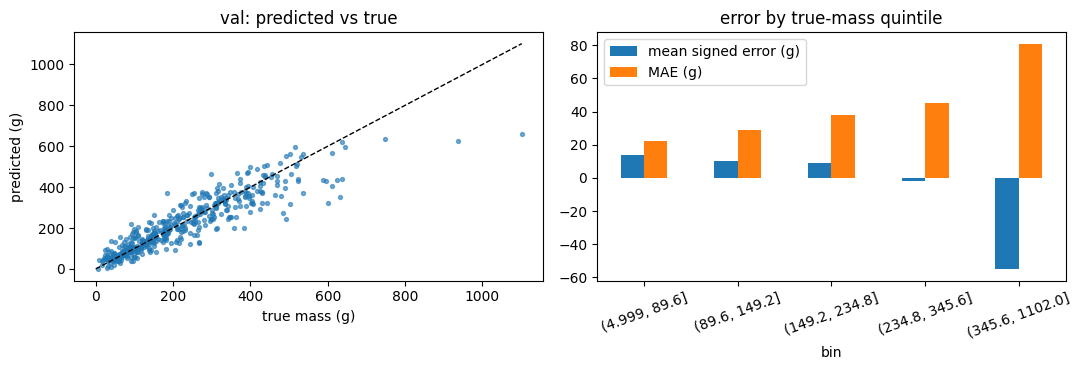

,mean signed error (g),MAE (g)
bin,,
"(4.999, 89.6]",13.5,22.5
"(89.6, 149.2]",10.1,28.7
"(149.2, 234.8]",9.0,38.1
"(234.8, 345.6]",-1.6,45.1
"(345.6, 1102.0]",-55.2,81.0


In [ ]:
# Where does C2 fail? Regression models trained with MSE shrink toward the mean:
# expect over-prediction on light plates and under-prediction on heavy ones.
err = p_va - y_va
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(y_va, p_va, s=8, alpha=.6); lim = [0, max(y_va.max(), p_va.max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlabel="true mass (g)", ylabel="predicted (g)", title="val: predicted vs true")
bins = pd.qcut(y_va, 5)
by = pd.DataFrame({"bin": bins, "err": err}).groupby("bin", observed=True)["err"].agg(["mean", lambda e: np.abs(e).mean()])
by.columns = ["mean signed error (g)", "MAE (g)"]
by.plot.bar(ax=ax[1], rot=20, title="error by true-mass quintile")
plt.tight_layout(); plt.savefig(OUT/"c2_diagnosis.png", dpi=150); plt.show()
by.round(1)

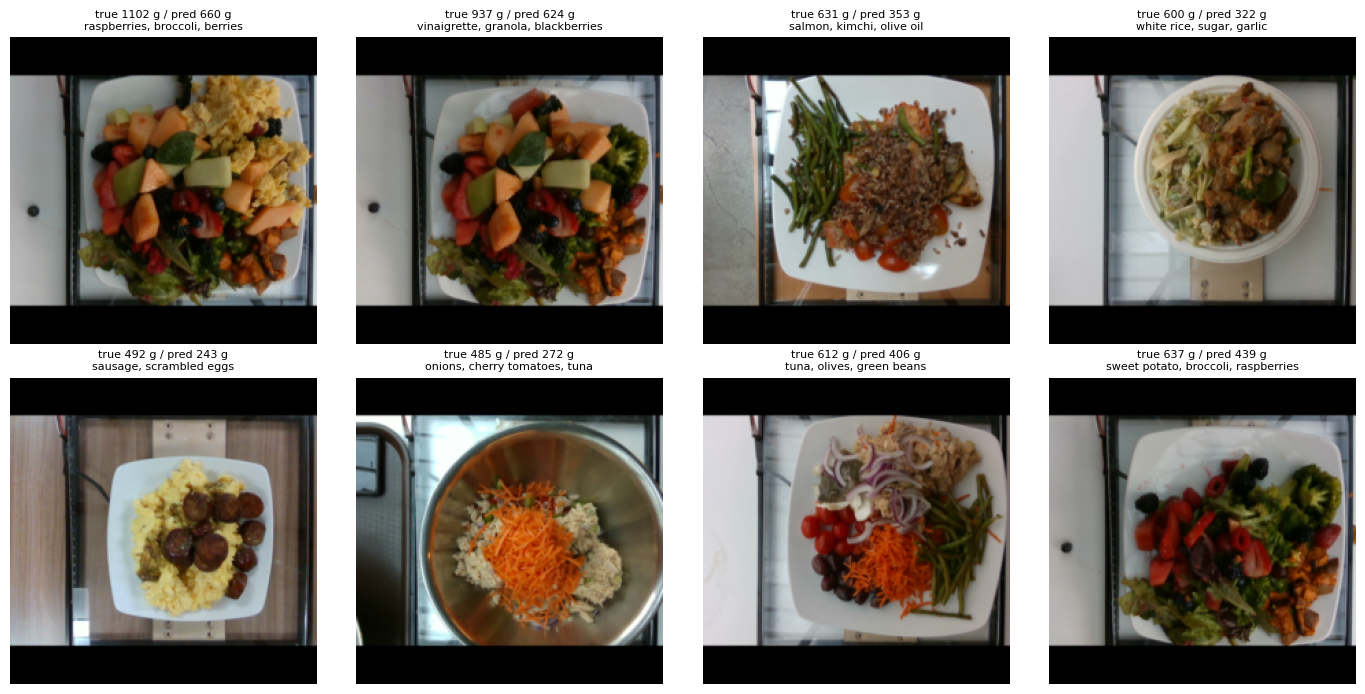

In [ ]:
# Inspect the worst predictions: look for empty plates, occluded food, liquids, or label errors.
worst = np.argsort(-np.abs(err))[:8]
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for a, i in zip(axs.flat, worst):
    a.imshow(X_va[i].permute(1, 2, 0)); a.axis("off")
    a.set_title(f"true {y_va[i]:.0f} g / pred {p_va[i]:.0f} g\n{', '.join(meta.at[val_ids[i],'ingr_names'][:3])}", fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"c2_worst.png", dpi=150); plt.show()
pd.DataFrame({"dish_id": val_ids, "true_g": y_va, "pred_g": p_va}).to_csv(OUT/"c2_val_predictions.csv", index=False)

## 9. Interface for C3 (hand this to P4)
`predict_mass(image) -> float grams`. Any RGB image (path, PIL, or H×W×3 uint8 array); the same pad-and-resize as training.

In [ ]:
def load_c2(path=OUT/"c2_best.pt"):
    ck = torch.load(path, map_location=DEVICE); m = make_model(pretrained=False)
    m.load_state_dict(ck["model"]); return m.to(DEVICE).eval(), ck["MU"], ck["SD"]

@torch.no_grad()
def predict_mass(image, c2=None):
    m, mu, sd = c2 or load_c2()
    im = Image.open(image) if isinstance(image, (str, Path)) else (Image.fromarray(image) if isinstance(image, np.ndarray) else image)
    im = im.convert("RGB"); w, h = im.size; s = max(w, h)
    sq = Image.new("RGB", (s, s)); sq.paste(im, ((s - w)//2, (s - h)//2))
    x = torch.from_numpy(np.array(sq.resize((CFG["IMG"],)*2, Image.BILINEAR))).permute(2, 0, 1)
    return float(m(eval_tf(x).unsqueeze(0).to(DEVICE)).item() * sd + mu)

C2 = load_c2()
print(f"{val_ids[0]}: predicted {predict_mass(img_path(val_ids[0]), C2):.0f} g, true {y_va[0]:.0f} g")

dish_1566333255: predicted 422 g, true 372 g


## 10. Final evaluation — run ONCE, after the team's code freeze
Leave `FINAL_EVAL=False` until then. Tuning anything after looking at test results invalidates the comparison.

In [ ]:
if CFG["FINAL_EVAL"]:
    X_te = build_cache(test_ids, "test"); y_te = meta.loc[test_ids, "total_mass"].values
    p_te = predict_grams(model, torch.utils.data.DataLoader(MassDS(X_te, test_ids, eval_tf), 64))
    final = pd.DataFrame({"test mass MAE (g)": [mae(y_te, MEDIAN), mae(y_te, p_te)], "n": [len(y_te)]*2},
                         index=["median baseline", "C2"]).round(1)
    final.to_csv(OUT/"c2_TEST_once.csv"); display(final)
else:
    print("FINAL_EVAL is off — test set untouched.")

FINAL_EVAL is off — test set untouched.
